# **TRAINING**

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Challenge2_nuova"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/Challenge2_nuova


In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph
from tqdm.notebook import tqdm

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


## ⏳ **Data Loading**

In [ ]:

def load_images_from_folder(folder, num_images, file_prefix='img'):
    """
    Load and preprocess images from a specified folder in sequential order.
    Checks for existing .npy files first to speed up loading.

    Args:
        folder (str): Path to the folder containing images
        num_images (int): The total number of images to load, determining the max ID.
        file_prefix (str): Prefix for the image files (e.g., 'img', 'mask').

    Returns:
        np.ndarray: Array of preprocessed images with shape (N, H, W, C)
    """

    # Define the base .npy filename (e.g., 'train_data_img.npy')
    npy_filename = os.path.basename(os.path.normpath(folder)) + f'_{file_prefix}.npy'

    print(f"Loading {npy_filename} from disk...")
    # Attempt to load the .npy file from the constructed full path
    return np.load(npy_filename)



# Load images from the folder
train_path = 'challenge_data/train_data/'
train_img = load_images_from_folder(train_path, num_images=691, file_prefix='img_560_new')

# Load images from the folder
test_path = 'challenge_data/test_data/'
test_img = load_images_from_folder(test_path, num_images=477, file_prefix='img_560_new')

print(f"Loaded {len(train_img)} train images")
print(f"Loaded {len(test_img)} test images")

Loading train_data_img_560_new.npy from disk...
Loading test_data_img_560_new.npy from disk...
Loaded 691 train images
Loaded 477 test images


## 🔎 **Exploration and Data Analysis**

Visualizzazione delle immagini del training set (train_img):
Displaying images from index 400 to 499 (total: 100)


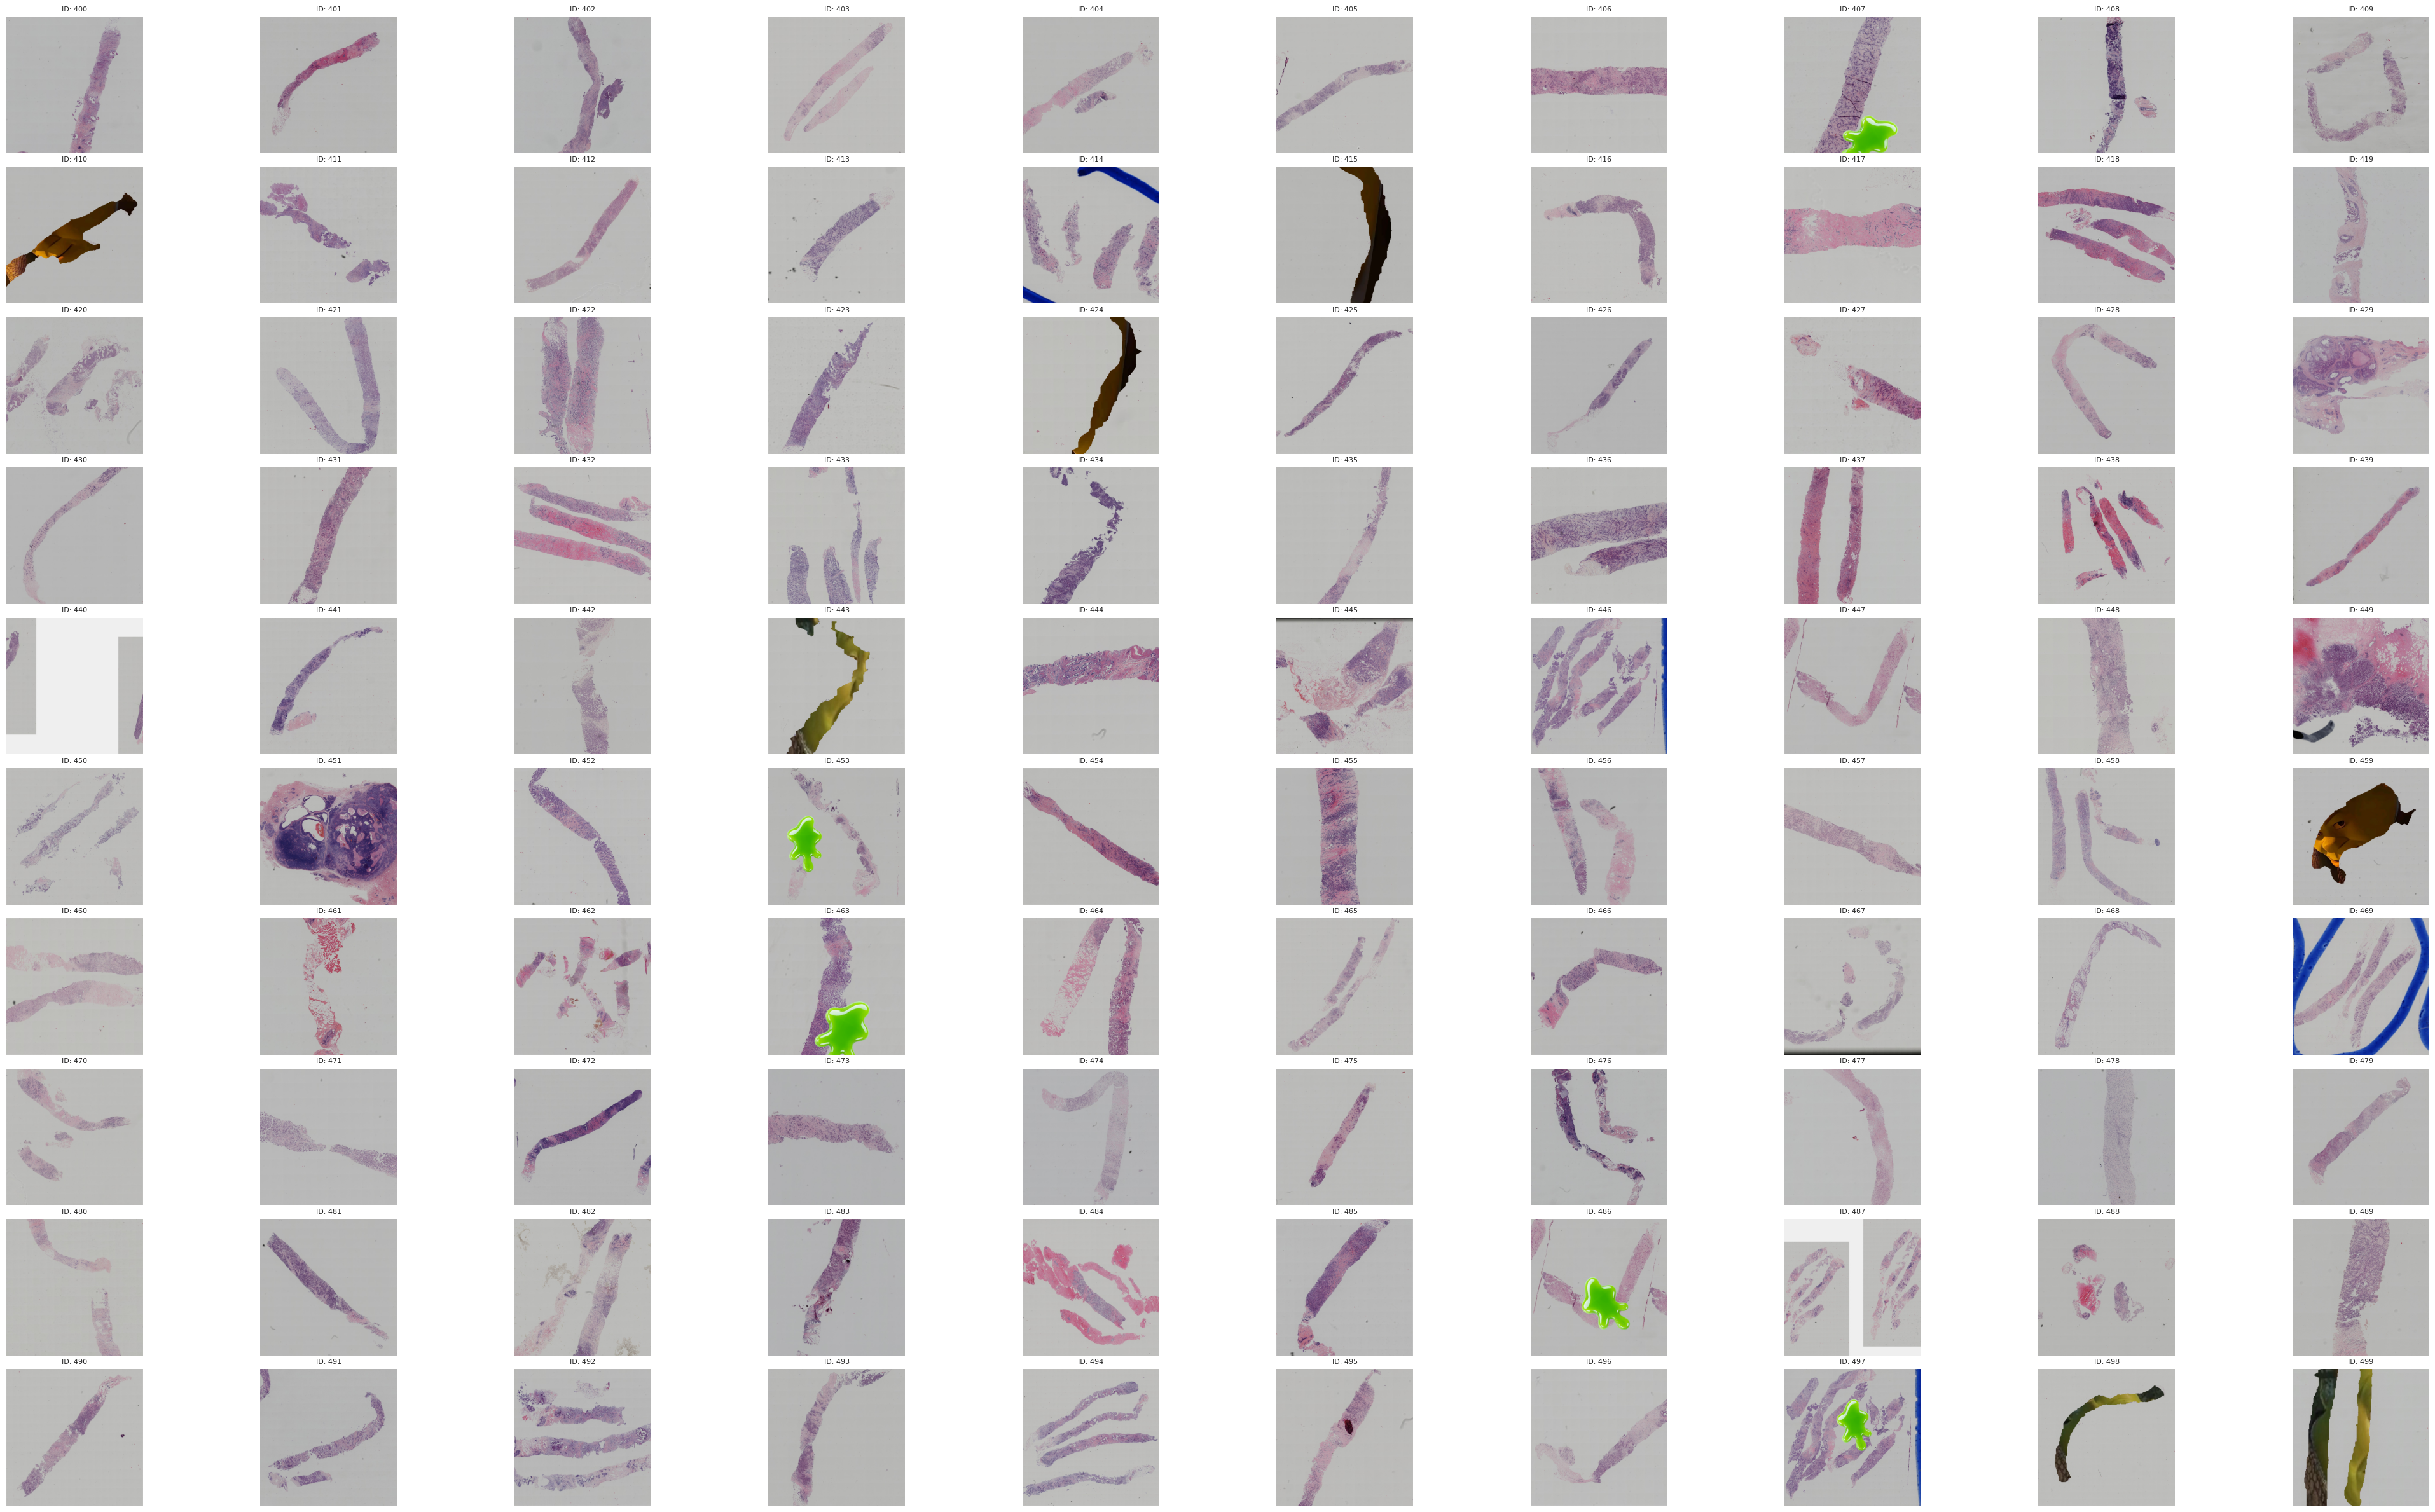

In [ ]:
def display_images_with_id(images, start_idx, end_idx, images_per_row=10, fig_size=(15, 6)):
    """
    Displays a range of images from a dataset in a grid, with their IDs.

    Args:
        images (np.ndarray): The dataset of images (N, H, W, C).
        start_idx (int): The starting index of images to display.
        end_idx (int): The ending index (exclusive) of images to display.
        images_per_row (int): Number of images to display per row.
        fig_size (tuple): Tuple for figure size (width, height).
    """
    num_images_to_display = end_idx - start_idx
    if num_images_to_display <= 0:
        print(f"No images to display in the range [{start_idx}, {end_idx})")
        return

    num_rows = (num_images_to_display + images_per_row - 1) // images_per_row

    fig = plt.figure(figsize=fig_size)
    gs = gridspec.GridSpec(num_rows, images_per_row, figure=fig)

    print(f"Displaying images from index {start_idx} to {end_idx-1} (total: {num_images_to_display})")

    for i, global_idx in enumerate(range(start_idx, end_idx)):
        if global_idx >= len(images):
            break

        row = i // images_per_row
        col = i % images_per_row

        ax = fig.add_subplot(gs[row, col])
        ax.imshow(np.clip(images[global_idx], 0, 1))  # Display clipped images
        ax.set_title(f"ID: {global_idx}", fontsize=8) # Display image ID
        ax.axis('off')

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    plt.show()

# --- Original display code (modified to use the new function and focus on train_img) ---

# Display a sample of train_img (e.g., first 20 images) as requested
# You can modify start_idx and end_idx to view different ranges of images.
print("Visualizzazione delle immagini del training set (train_img):")
display_images_with_id(train_img, start_idx=400, end_idx=500, images_per_row=10, fig_size=(40, 24))

# The test_img display code is removed as the user requested only train_img.
# If you need to display test_img, you can call:
# display_images_with_id(test_img, start_idx=0, end_idx=20, images_per_row=10, fig_size=(18, 4))

## 🔄 **Data Preprocessing**

In [ ]:
# Concatenate 'animals' and 'items' arrays along axis 0
X_train = train_img;
X_test = test_img;
y_train = pd.read_csv("challenge_data/train_labels.csv")["label"];

# Clean up the dataset, removing shrek and scracchio images
imgs_to_remove = [1, 5, 8, 12, 18, 20, 22, 25, 27, 28, 36, 47, 48, 52,
                        62, 78, 85, 90, 94, 95, 126, 129, 130, 133, 136, 138,
                        148, 150, 155, 159, 161, 175, 178, 179, 180, 187, 189, 193, 196, 222, 237,
                        251, 253, 254, 263, 268, 270, 286, 293, 313, 319, 333, 342, 344, 346, 355,
                        368, 371, 376, 380, 390, 393, 407, 410, 415, 424, 440, 443, 453, 459, 463,
                        486, 497, 498, 499, 509, 521, 530, 531, 533, 537, 540, 544, 547, 557, 558,
                        560, 565, 567, 572, 576, 578, 580, 586, 602, 603, 607, 609, 614, 620, 623,
                        629, 635, 639, 643, 644, 645, 646, 656, 657, 658, 670, 673, 675]

# Create a mask for images to keep (indices NOT in imgs_to_remove)
all_indices = np.arange(len(X_train))
indices_to_keep = np.setdiff1d(all_indices, imgs_to_remove)

# Filter X_train and y_train
X_train = X_train[indices_to_keep]
y_train = y_train.iloc[indices_to_keep]

print(f"Original Training Data Shape: {train_img.shape} -> Cleaned: {X_train.shape}")

# Define a mapping of classes to integer labels
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3,
}

y_train = y_train.map(label_mapping);

# Further split train_val into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
   X_train, y_train, random_state=SEED, test_size=0.15, stratify=y_train
)

# Print shapes of the datasets
print(f"Training Data Shape: {X_train.shape}")
print(f"Training Label Shape: {y_train.shape}")
print(f"Validation Data Shape: {X_val.shape}")
print(f"Validation Label Shape: {y_val.shape}")
print(f"Test Data Shape: {X_test.shape}")

Original Training Data Shape: (691, 560, 560, 3) -> Cleaned: (577, 560, 560, 3)
Training Data Shape: (490, 560, 560, 3)
Training Label Shape: (490,)
Validation Data Shape: (87, 560, 560, 3)
Validation Label Shape: (87,)
Test Data Shape: (477, 560, 560, 3)


In [ ]:
# Define the input shape based on the training data
input_shape = (X_train.shape[3], X_train.shape[1], X_train.shape[2])

# Define the number of classes
num_classes = len(np.unique(y_train))

print("Input Shape:", input_shape)
print("Number of Classes:", num_classes)

Input Shape: (3, 560, 560)
Number of Classes: 4


In [ ]:
# Define the batch size
BATCH_SIZE = 32

In [ ]:
# ImageNet normalization statistics
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class chaldataset(torch.utils.data.Dataset):

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data)
        self.labels = torch.from_numpy(labels).long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Permute image dimensions from HWC to CHW
        image = image.permute(2, 0, 1)

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [ ]:
def make_loader(ds, batch_size, shuffle, drop_last, sampler=None):
    """Create a PyTorch DataLoader with optimized settings."""
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,
        sampler=sampler # Added sampler argument here
    )

##  🧮 **Network Parameters**

In [ ]:
# Training parameters
LEARNING_RATE = 1e-4
EPOCHS = 500
PATIENCE = 30

# Regularization
DROPOUT_RATE = 0.4

criterion = nn.CrossEntropyLoss()

# Print the defined parameters
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Dropout Rate:", DROPOUT_RATE)
print("Patience:", PATIENCE)

Epochs: 500
Batch Size: 32
Learning Rate: 0.0001
Dropout Rate: 0.4
Patience: 30


##  🧠 **Training Functions**

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = accuracy_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions)
    )

    return epoch_loss, epoch_acc


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = accuracy_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions)
    )

    return epoch_loss, epoch_accuracy


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_acc", mode='max',
        restore_best_weights=True, writer=None, verbose=1, experiment_name="", scheduler=None):
    """Train the neural network model."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        val_loss, val_acc = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_acc'].append(train_acc)
        training_history['val_acc'].append(val_acc)

        # Step the scheduler if provided
        if scheduler:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if writer is not None:
            writer.add_scalar('Loss/Training', train_loss, epoch)
            writer.add_scalar('Loss/Validation', val_loss, epoch)
            writer.add_scalar('Accuracy/Training', train_acc, epoch)
            writer.add_scalar('Accuracy/Validation', val_acc, epoch)

        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
                    f"Val: Loss={val_loss:.4f}, Acc={val_acc:.4f}")

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+"_model.pt"))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    if writer is not None:
        writer.close()

    return model, training_history

In [ ]:
# Image augmentation
train_augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=72, translate=(0.2, 0.2), scale=(0.8, 1.2)),
    transforms.ColorJitter(brightness=0.1, contrast=0.3, saturation=0.3),
    transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 0.5)),
])

## 🛠️ **Model Building**

In [ ]:
!pip install timm

In [ ]:
import torch
import torch.nn as nn
import torchvision
import timm

# --- HELPER CLASS: Simple CNN Vanilla ---
class VanillaCNN(nn.Module):
    """A simple convolutional neural network, not pretrained."""
    def __init__(self, num_classes, dropout_rate=0.3, input_channels=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1)) # Reduces spatial dims to 1x1, keeping channels
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes) # 128 is the number of channels from the last conv layer
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1) # Flatten all dimensions except batch
        x = self.classifier(x)
        return x

# --- MODEL DEFINITION (Flexible Backbone) ---
class GenericTransferLearning(nn.Module):
    """A flexible transfer learning model capable of using different backbones."""

    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True, model_name='resnet50'):
        super().__init__()

        self.model_name = model_name

        if model_name == 'vanilla_cnn':
            self.backbone = VanillaCNN(num_classes, dropout_rate)
            # For vanilla CNN, the head is already part of its internal structure
            # Freezing would apply to its features
            if freeze_backbone:
                for param in self.backbone.features.parameters():
                    param.requires_grad = False
                # Ensure the classifier is always trainable
                for param in self.backbone.classifier.parameters():
                    param.requires_grad = True
            else: # If not freezing, ensure all params are trainable
                 for param in self.backbone.parameters():
                    param.requires_grad = True

        elif model_name == 'efficientnet_b0':
            self.backbone = torchvision.models.efficientnet_b0(
                weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT
            )
            in_features = self.backbone.classifier[1].in_features
            # Replace Classifier Head for EfficientNet
            self.backbone.classifier[1] = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            # Freeze backbone features after the head is set
            if freeze_backbone:
                for param in self.backbone.features.parameters(): # Target only features
                    param.requires_grad = False
            # Ensure the new classifier head is trainable
            for param in self.backbone.classifier.parameters():
                param.requires_grad = True

        elif model_name.startswith('resnet'):
            if model_name == 'resnet18':
                self.backbone = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
            elif model_name == 'resnet34':
                self.backbone = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.DEFAULT)
            elif model_name == 'resnet50':
                self.backbone = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT)
            elif model_name == 'resnet101':
                self.backbone = torchvision.models.resnet101(weights=torchvision.models.ResNet101_Weights.DEFAULT)
            elif model_name == 'resnet152':
                self.backbone = torchvision.models.resnet152(weights=torchvision.models.ResNet152_Weights.DEFAULT)
            else:
                raise ValueError(f"Unsupported ResNet model: {model_name}. Choose from resnet18, resnet34, resnet50, resnet101, resnet152.")

            in_features = self.backbone.fc.in_features
            # Replace Classifier Head for ResNet
            self.backbone.fc = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            # Freeze backbone parameters if requested
            if freeze_backbone:
                for param in self.backbone.parameters():
                    param.requires_grad = False
                # Ensure the new fc layer is trainable
                for param in self.backbone.fc.parameters():
                    param.requires_grad = True

        elif model_name == 'swin_tiny':
            self.backbone = torchvision.models.swin_t(
                weights=torchvision.models.Swin_T_Weights.DEFAULT
            )
            in_features = self.backbone.head.in_features
            # Replace Classifier Head for Swin Transformer
            self.backbone.head = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            # Freeze backbone features after the head is set
            if freeze_backbone:
                # Swin Transformer's features are within the 'features' attribute
                for param in self.backbone.features.parameters():
                    param.requires_grad = False
            # Ensure the new classifier head is trainable
            for param in self.backbone.head.parameters():
                param.requires_grad = True

        elif model_name == 'swin_small':
            self.backbone = torchvision.models.swin_s(
                weights=torchvision.models.Swin_S_Weights.DEFAULT
            )
            in_features = self.backbone.head.in_features
            self.backbone.head = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            if freeze_backbone:
                for param in self.backbone.features.parameters():
                    param.requires_grad = False
            for param in self.backbone.head.parameters():
                param.requires_grad = True

        elif model_name == 'swin_base':
            self.backbone = torchvision.models.swin_b(
                weights=torchvision.models.Swin_B_Weights.DEFAULT
            )
            in_features = self.backbone.head.in_features
            self.backbone.head = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            if freeze_backbone:
                for param in self.backbone.features.parameters():
                    param.requires_grad = False
            for param in self.backbone.head.parameters():
                param.requires_grad = True

        elif model_name == 'swin_large':
            self.backbone = torchvision.models.swin_l(
                weights=torchvision.models.Swin_L_Weights.DEFAULT
            )
            in_features = self.backbone.head.in_features
            self.backbone.head = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes)
            )
            if freeze_backbone:
                for param in self.backbone.features.parameters():
                    param.requires_grad = False
            for param in self.backbone.head.parameters():
                param.requires_grad = True

        else:
            raise ValueError(f"Model '{model_name}' not supported.")


    def forward(self, x):
        return self.backbone(x)

    def unfreeze_last_stage(self):
        """Unfreeze the last stage for fine-tuning based on the model."""
        if self.model_name == 'vanilla_cnn':
            # For VanillaCNN, unfreeze the last convolutional block and its classifier
            for param in self.backbone.features[-3:].parameters(): # Last Conv2d, ReLU, MaxPool2d
                param.requires_grad = True
            for param in self.backbone.classifier.parameters(): # Ensure classifier is trainable
                param.requires_grad = True
            print("Info: Last convolutional block of VanillaCNN unfrozen for training.")

        elif self.model_name == 'efficientnet_b0':
            # EfficientNet last block (features.6 for B0-B7) and then features.7 (last block before classifier)
            # We'll unfreeze the last block (block 6 - features[6]) and the final layer (features[8] which is the Conv2d for 1280 channels)
            for param in self.backbone.features[6].parameters():
                param.requires_grad = True
            for param in self.backbone.features[7].parameters():
                param.requires_grad = True
            for param in self.backbone.features[8].parameters(): # Last conv layer before avgpool
                param.requires_grad = True
            print("Info: Last three blocks (EfficientNet features[6], features[7], features[8]) unfrozen for training.")

        elif self.model_name.startswith('resnet'):
            # ResNet typically has layer1, layer2, layer3, layer4. Unfreeze layer4.
            for param in self.backbone.layer4.parameters():
                param.requires_grad = True
            print(f"Info: Last stage ({self.model_name} layer4) unfrozen for training.")
            # The classifier (fc) is already trainable from init, no need to explicitly unfreeze here.

        elif 'swin' in self.model_name: # Generic for all Swin variants from torchvision
            # Swin Transformer's last stage in torchvision models is usually in self.backbone.features[-1]
            if hasattr(self.backbone, 'features') and len(self.backbone.features) > 0:
                for param in self.backbone.features[-1].parameters():
                    param.requires_grad = True
                print(f"Info: Last stage (Swin Transformer {self.model_name} features[-1]) unfrozen for training.")
            else:
                print(f"Warning: Could not find features attribute for Swin Transformer {self.model_name} to unfreeze.")

        else:
            print(f"Warning: Unfreeze operation not defined for model: {self.model_name}")

### **Vanilla CNN**

In [ ]:
# Model's istance
tf_model_swin = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True,
    model_name='vanilla_cnn'
).to(device)

# Visualizza il riepilogo del modello
summary(tf_model_swin, input_size=input_shape)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 560, 560]             896
              ReLU-2         [-1, 32, 560, 560]               0
         MaxPool2d-3         [-1, 32, 280, 280]               0
            Conv2d-4         [-1, 64, 280, 280]          18,496
              ReLU-5         [-1, 64, 280, 280]               0
         MaxPool2d-6         [-1, 64, 140, 140]               0
            Conv2d-7        [-1, 128, 140, 140]          73,856
              ReLU-8        [-1, 128, 140, 140]               0
         MaxPool2d-9          [-1, 128, 70, 70]               0
AdaptiveAvgPool2d-10            [-1, 128, 1, 1]               0
          Dropout-11                  [-1, 128]               0
           Linear-12                    [-1, 4]             516
       VanillaCNN-13                    [-1, 4]               0
Total params: 93,764
Trainable params: 

In [ ]:
# Create datasets WITH ImageNet normalization (for pretrained model)
train_tl_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_tl_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_tl_loader = make_loader(train_tl_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_tl_loader = make_loader(val_tl_ds, BATCH_SIZE, shuffle=False, drop_last=False)

print("Recreated train and validation data loaders for transfer learning.")

Recreated train and validation data loaders for transfer learning.


In [ ]:
import torch.optim.lr_scheduler

# Setup training
experiment_name = "vanilla_CNN"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(tf_model_swin.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize scheduler_tl as a ReduceLROnPlateau scheduler
scheduler_tl = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10,
    min_lr=1e-7
)

In [ ]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tf_model_swin,
    train_loader=train_tl_loader,
    val_loader=val_tl_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE,
    scheduler=scheduler_tl
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3979, Acc=0.1776 | Val: Loss=1.3975, Acc=0.1149
Epoch   2/500 | Train: Loss=1.3929, Acc=0.2020 | Val: Loss=1.3956, Acc=0.1149
Epoch   3/500 | Train: Loss=1.3941, Acc=0.1939 | Val: Loss=1.3938, Acc=0.1379
Epoch   4/500 | Train: Loss=1.3903, Acc=0.2143 | Val: Loss=1.3919, Acc=0.2414
Epoch   5/500 | Train: Loss=1.3915, Acc=0.2224 | Val: Loss=1.3902, Acc=0.2874
Epoch   6/500 | Train: Loss=1.3860, Acc=0.2653 | Val: Loss=1.3884, Acc=0.2759
Epoch   7/500 | Train: Loss=1.3839, Acc=0.2714 | Val: Loss=1.3866, Acc=0.2759
Epoch   8/500 | Train: Loss=1.3829, Acc=0.2980 | Val: Loss=1.3850, Acc=0.2759
Epoch   9/500 | Train: Loss=1.3782, Acc=0.3245 | Val: Loss=1.3833, Acc=0.2759
Epoch  10/500 | Train: Loss=1.3791, Acc=0.2898 | Val: Loss=1.3818, Acc=0.2759
Epoch  11/500 | Train: Loss=1.3792, Acc=0.2714 | Val: Loss=1.3801, Acc=0.2759
Epoch  12/500 | Train: Loss=1.3743, Acc=0.3204 | Val: Loss=1.3787, Acc=0.2759
Epoch  13/500 | Train: Loss=1.3735, Acc=0

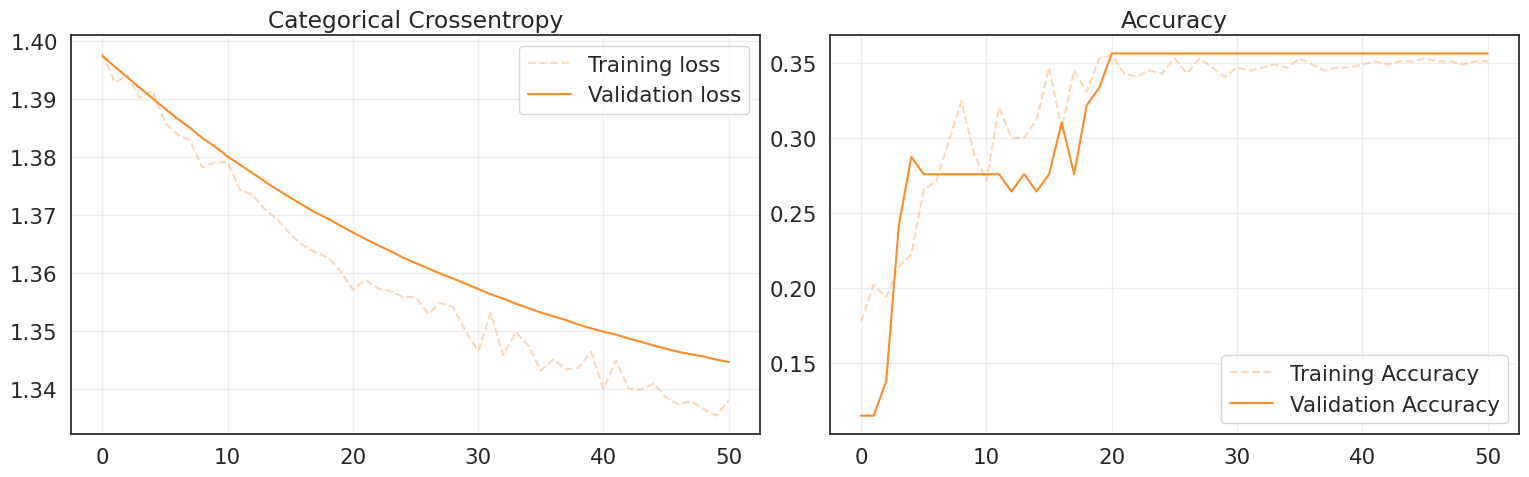

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_acc'], label='Training Accuracy', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_acc'], label='Validation Accuracy', alpha=0.9, color='#ff7f0e')
ax2.set_title('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.3563
Precision over the validation set: 0.1270
Recall over the validation set: 0.3563
F1 score over the validation set: 0.1872


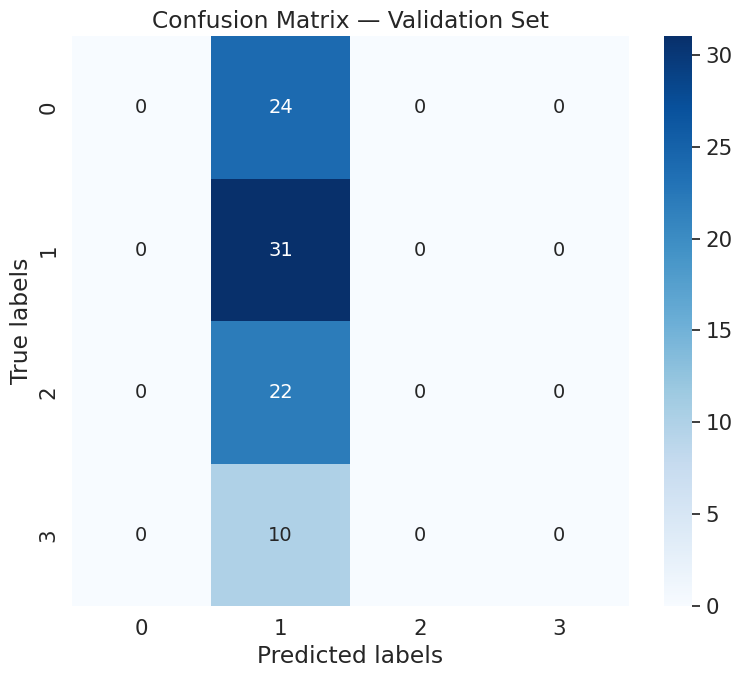

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_tl_loader: # Modificato da val_aug_loader a val_tl_loader
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = tl_model(xb) # Modificato da aug_model a tl_model
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### **EfficientNetB0**

In [ ]:
# Model's istance
tf_model_swin = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True,
    model_name='efficientnet_b0'
).to(device)

# Visualizza il riepilogo del modello
summary(tf_model_swin, input_size=input_shape)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 280, 280]             864
       BatchNorm2d-2         [-1, 32, 280, 280]              64
              SiLU-3         [-1, 32, 280, 280]               0
            Conv2d-4         [-1, 32, 280, 280]             288
       BatchNorm2d-5         [-1, 32, 280, 280]              64
              SiLU-6         [-1, 32, 280, 280]               0
 AdaptiveAvgPool2d-7             [-1, 32, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             264
              SiLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 32, 1, 1]             288
          Sigmoid-11             [-1, 32, 1, 1]               0
SqueezeExcitation-12         [-1, 32, 280, 280]               0
           Conv2d-13         [-1, 16, 280, 280]             512
      BatchNorm2d-14         [-1, 16, 2

In [ ]:
# Create datasets WITH ImageNet normalization (for pretrained model)
train_tl_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_tl_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_tl_loader = make_loader(train_tl_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_tl_loader = make_loader(val_tl_ds, BATCH_SIZE, shuffle=False, drop_last=False)

PATIENCE = 20

print("Recreated train and validation data loaders for transfer learning.")

Recreated train and validation data loaders for transfer learning.


In [ ]:
import torch.optim.lr_scheduler

# Setup training
experiment_name = "EfficientNetB0"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(tf_model_swin.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize scheduler_tl as a ReduceLROnPlateau scheduler
scheduler_tl = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10,
    min_lr=1e-7
)

In [ ]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tf_model_swin,
    train_loader=train_tl_loader,
    val_loader=val_tl_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE,
    scheduler=scheduler_tl
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3877, Acc=0.2551 | Val: Loss=1.3564, Acc=0.2759
Epoch   2/500 | Train: Loss=1.3590, Acc=0.3122 | Val: Loss=1.3462, Acc=0.3103
Epoch   3/500 | Train: Loss=1.3446, Acc=0.3163 | Val: Loss=1.3398, Acc=0.4023
Epoch   4/500 | Train: Loss=1.3479, Acc=0.3245 | Val: Loss=1.3396, Acc=0.3793
Epoch   5/500 | Train: Loss=1.3230, Acc=0.3388 | Val: Loss=1.3384, Acc=0.3678
Epoch   6/500 | Train: Loss=1.3372, Acc=0.3449 | Val: Loss=1.3371, Acc=0.3793
Epoch   7/500 | Train: Loss=1.3410, Acc=0.3388 | Val: Loss=1.3366, Acc=0.4023
Epoch   8/500 | Train: Loss=1.3276, Acc=0.3347 | Val: Loss=1.3356, Acc=0.3908
Epoch   9/500 | Train: Loss=1.3231, Acc=0.3612 | Val: Loss=1.3372, Acc=0.3563
Epoch  10/500 | Train: Loss=1.3188, Acc=0.3388 | Val: Loss=1.3392, Acc=0.3448
Epoch  11/500 | Train: Loss=1.3325, Acc=0.3469 | Val: Loss=1.3395, Acc=0.3793
Epoch  12/500 | Train: Loss=1.3131, Acc=0.3510 | Val: Loss=1.3390, Acc=0.3563
Epoch  13/500 | Train: Loss=1.3225, Acc=0

In [ ]:
# Load the transfer learning model

ft_model = GenericTransferLearning(num_classes, DROPOUT_RATE, freeze_backbone=False, model_name='efficientnet_b0').to(device)
ft_model.load_state_dict(torch.load("models/EfficientNetB0_model.pt"))

# Unfreeze the last N layers of the backbone
N_LAYERS_TO_UNFREEZE = 20

# Strategy: Freeze everything first, then unfreeze the last few blocks
for param in ft_model.parameters():
    param.requires_grad = False

# The classifier is always trainable
for param in ft_model.backbone.classifier.parameters():
    param.requires_grad = True

# Unfreeze the last 2 blocks of the feature extractor (EfficientNet-B0 has 9 blocks usually)
# Adjust slice index [-2:] to unfreeze more or fewer layers
for block in ft_model.backbone.features[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Check trainable parameters
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

Trainable parameters: 1,134,516 / 4,012,672


In [ ]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_ft_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning_effnet"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
# Filter parameters to only include those that require gradients
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, ft_model.parameters()), lr=1e-4) # 10x smaller LR
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
%%time
# Fine-tune the model
# Pass 'ft_model' to the fit function, as this is the model intended for fine-tuning
# Also, update 'ft_model' with the results of the fine-tuning
ft_model, tl_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3262, Acc=0.3224 | Val: Loss=1.3387, Acc=0.3448
Epoch   5/500 | Train: Loss=1.2842, Acc=0.3816 | Val: Loss=1.3471, Acc=0.3218
Epoch  10/500 | Train: Loss=1.2448, Acc=0.4245 | Val: Loss=1.3606, Acc=0.2989
Epoch  15/500 | Train: Loss=1.2215, Acc=0.4531 | Val: Loss=1.3682, Acc=0.3218
Epoch  20/500 | Train: Loss=1.2006, Acc=0.4694 | Val: Loss=1.3808, Acc=0.3103
Epoch  25/500 | Train: Loss=1.1717, Acc=0.4857 | Val: Loss=1.3816, Acc=0.2874
Epoch  30/500 | Train: Loss=1.1363, Acc=0.4776 | Val: Loss=1.3993, Acc=0.2989
Epoch  35/500 | Train: Loss=1.1071, Acc=0.5204 | Val: Loss=1.3871, Acc=0.3448
Early stopping triggered after 38 epochs.
Best model restored from epoch 18 with val_acc 0.3563
Final validation accuracy: 35.63%
CPU times: user 1min 26s, sys: 35.5 s, total: 2min 2s
Wall time: 9min 29s


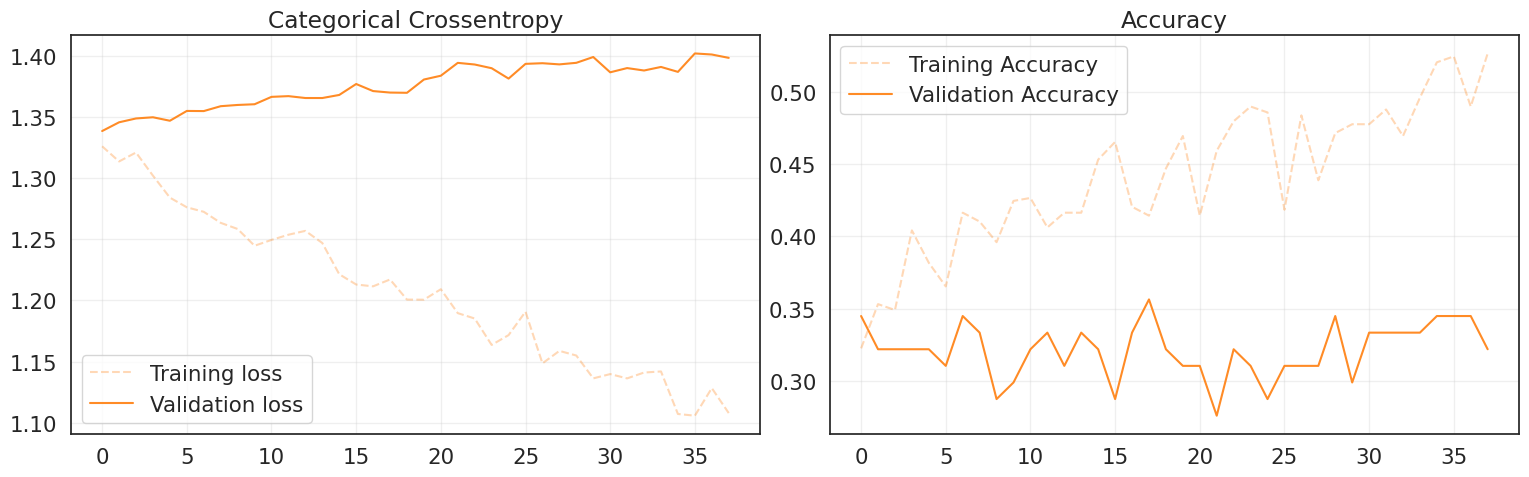

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_acc'], label='Training Accuracy', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_acc'], label='Validation Accuracy', alpha=0.9, color='#ff7f0e')
ax2.set_title('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.3563
Precision over the validation set: 0.3551
Recall over the validation set: 0.3563
F1 score over the validation set: 0.3266


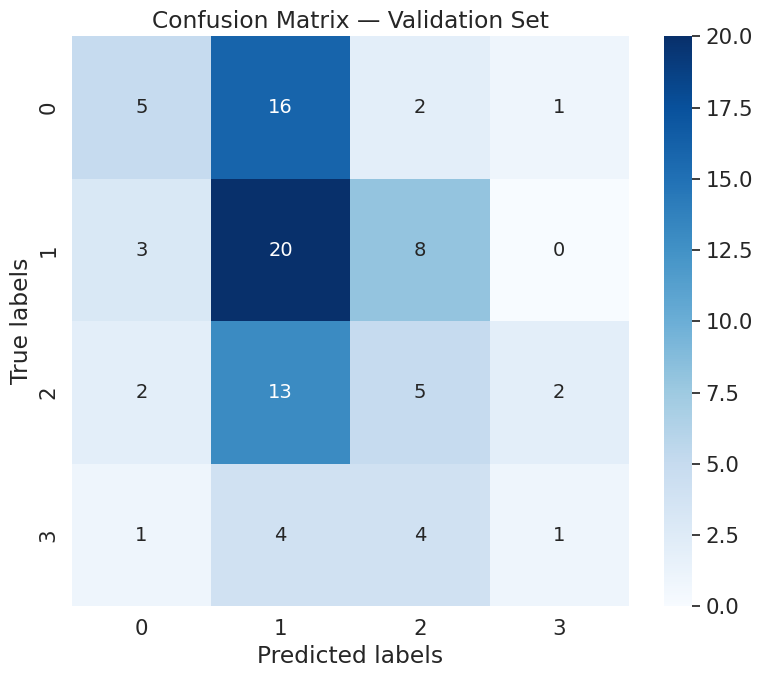

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_ft_loader: # Modificato da val_aug_loader a val_tl_loader
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = ft_model(xb) # Modificato da aug_model a tl_model
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### **ResNet**

In [57]:
# Model's istance
tf_model_swin = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True,
    model_name='resnet18'
).to(device)

# Visualizza il riepilogo del modello
summary(tf_model_swin, input_size=input_shape)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 65.3MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 280, 280]           9,408
       BatchNorm2d-2         [-1, 64, 280, 280]             128
              ReLU-3         [-1, 64, 280, 280]               0
         MaxPool2d-4         [-1, 64, 140, 140]               0
            Conv2d-5         [-1, 64, 140, 140]          36,864
       BatchNorm2d-6         [-1, 64, 140, 140]             128
              ReLU-7         [-1, 64, 140, 140]               0
            Conv2d-8         [-1, 64, 140, 140]          36,864
       BatchNorm2d-9         [-1, 64, 140, 140]             128
             ReLU-10         [-1, 64, 140, 140]               0
       BasicBlock-11         [-1, 64, 140, 140]               0
           Conv2d-12         [-1, 64, 140, 140]          36,864
      BatchNorm2d-13         [-1, 64, 140, 140]             128
             ReLU-14         [-1, 64, 1

In [58]:
# Create datasets WITH ImageNet normalization (for pretrained model)
train_tl_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_tl_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_tl_loader = make_loader(train_tl_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_tl_loader = make_loader(val_tl_ds, BATCH_SIZE, shuffle=False, drop_last=False)

print("Recreated train and validation data loaders for transfer learning.")

Recreated train and validation data loaders for transfer learning.


In [60]:
import torch.optim.lr_scheduler

# Setup training
experiment_name = "ResNet18"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(tf_model_swin.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize scheduler_tl as a ReduceLROnPlateau scheduler
scheduler_tl = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10,
    min_lr=1e-7
)

PATIENCE = 10

In [61]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tf_model_swin,
    train_loader=train_tl_loader,
    val_loader=val_tl_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE,
    scheduler=scheduler_tl
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.4591, Acc=0.2959 | Val: Loss=1.3561, Acc=0.2989
Epoch   2/500 | Train: Loss=1.3891, Acc=0.3000 | Val: Loss=1.3251, Acc=0.3448
Epoch   3/500 | Train: Loss=1.4289, Acc=0.2959 | Val: Loss=1.3190, Acc=0.3563
Epoch   4/500 | Train: Loss=1.3746, Acc=0.3571 | Val: Loss=1.3205, Acc=0.3678
Epoch   5/500 | Train: Loss=1.4114, Acc=0.3102 | Val: Loss=1.3192, Acc=0.3678
Epoch   6/500 | Train: Loss=1.4263, Acc=0.2816 | Val: Loss=1.3239, Acc=0.3563
Epoch   7/500 | Train: Loss=1.4176, Acc=0.3143 | Val: Loss=1.3205, Acc=0.3908
Epoch   8/500 | Train: Loss=1.3927, Acc=0.3122 | Val: Loss=1.3183, Acc=0.3793
Epoch   9/500 | Train: Loss=1.4141, Acc=0.2796 | Val: Loss=1.3229, Acc=0.3103
Epoch  10/500 | Train: Loss=1.3993, Acc=0.3245 | Val: Loss=1.3229, Acc=0.3563
Epoch  11/500 | Train: Loss=1.4071, Acc=0.3000 | Val: Loss=1.3228, Acc=0.4023
Epoch  12/500 | Train: Loss=1.4165, Acc=0.2980 | Val: Loss=1.3164, Acc=0.3678
Epoch  13/500 | Train: Loss=1.4375, Acc=0

In [62]:
# Load the transfer learning model for fine-tuning
ft_model = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True, # Start with backbone frozen, as unfreeze_last_stage will selectively unfreeze
    model_name='resnet18' # Crucially, specify the correct model name
).to(device)

# Load the best weights from the previous transfer learning step
ft_model.load_state_dict(torch.load("models/ResNet18_model.pt"))

# Unfreeze the last layers of the backbone using the dedicated method
ft_model.unfreeze_last_stage()

# Check trainable parameters
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

Info: Last stage (resnet18 layer4) unfrozen for training.
Trainable parameters: 8,395,780 / 11,178,564


In [63]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning_resnet"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4) # 10x smaller LR
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [64]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_ft_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [65]:
%%time
# Fine-tune the model
ft_model, tl_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3976, Acc=0.3306 | Val: Loss=1.3054, Acc=0.4023
Epoch   5/500 | Train: Loss=1.2961, Acc=0.3837 | Val: Loss=1.3583, Acc=0.3908
Epoch  10/500 | Train: Loss=1.2423, Acc=0.4327 | Val: Loss=1.3044, Acc=0.3908
Epoch  15/500 | Train: Loss=1.1872, Acc=0.4204 | Val: Loss=1.3277, Acc=0.3218
Epoch  20/500 | Train: Loss=1.1710, Acc=0.4633 | Val: Loss=1.3103, Acc=0.3793
Early stopping triggered after 21 epochs.
Best model restored from epoch 11 with val_acc 0.4253
Final validation accuracy: 42.53%
CPU times: user 36.9 s, sys: 17.8 s, total: 54.7 s
Wall time: 4min 13s


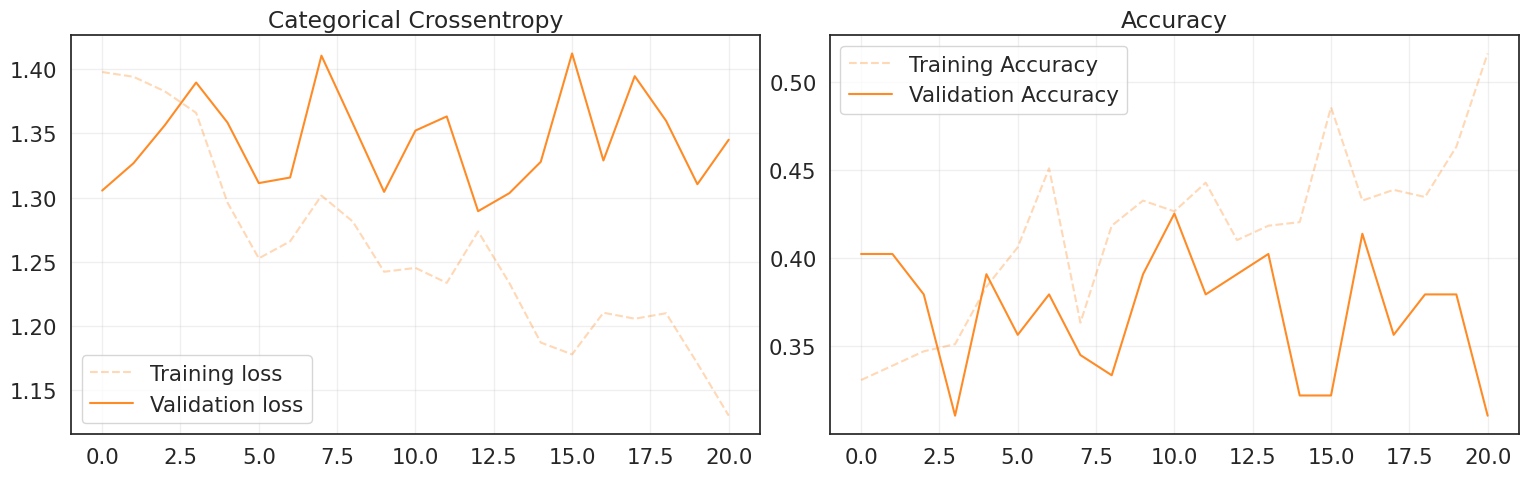

In [66]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_acc'], label='Training Accuracy', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_acc'], label='Validation Accuracy', alpha=0.9, color='#ff7f0e')
ax2.set_title('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.4138
Precision over the validation set: 0.4012
Recall over the validation set: 0.4138
F1 score over the validation set: 0.3847


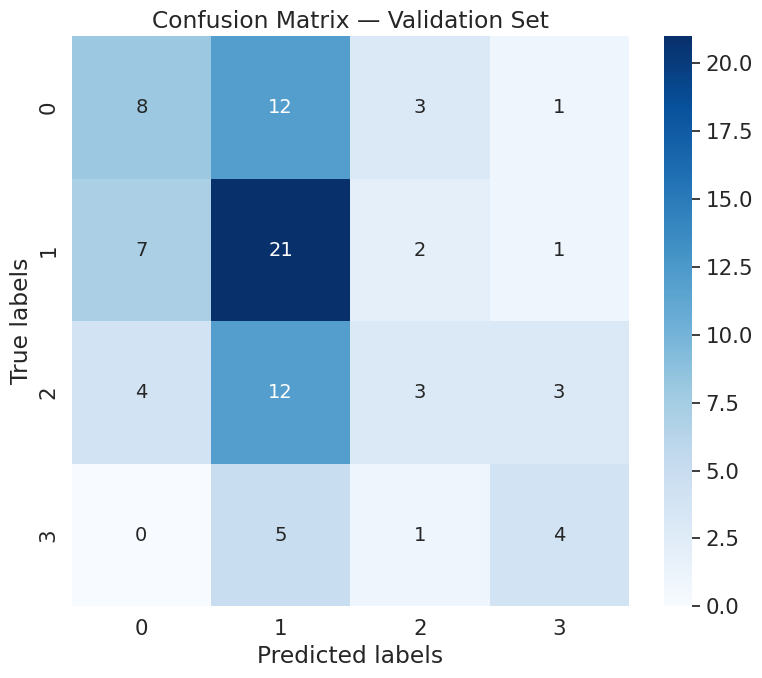

In [67]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_ft_loader: # Modificato da val_aug_loader a val_tl_loader
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = ft_model(xb) # Modificato da aug_model a tl_model
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

### **SwinTransformer**

In [ ]:
# Model's istance
tf_model_swin = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True,
    model_name='swin_small'
).to(device)

# Visualizza il riepilogo del modello
summary(tf_model_swin, input_size=input_shape)

Downloading: "https://download.pytorch.org/models/swin_s-5e29d889.pth" to /root/.cache/torch/hub/checkpoints/swin_s-5e29d889.pth


100%|██████████| 190M/190M [00:07<00:00, 27.4MB/s]


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 96, 140, 140]           4,704
           Permute-2         [-1, 140, 140, 96]               0
         LayerNorm-3         [-1, 140, 140, 96]             192
         LayerNorm-4         [-1, 140, 140, 96]             192
ShiftedWindowAttention-5         [-1, 140, 140, 96]               0
   StochasticDepth-6         [-1, 140, 140, 96]               0
         LayerNorm-7         [-1, 140, 140, 96]             192
            Linear-8        [-1, 140, 140, 384]          37,248
              GELU-9        [-1, 140, 140, 384]               0
          Dropout-10        [-1, 140, 140, 384]               0
           Linear-11         [-1, 140, 140, 96]          36,960
          Dropout-12         [-1, 140, 140, 96]               0
  StochasticDepth-13         [-1, 140, 140, 96]               0
SwinTransformerBlock-14         [-1

In [ ]:
# Create datasets WITH ImageNet normalization (for pretrained model)
train_tl_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_tl_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_tl_loader = make_loader(train_tl_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_tl_loader = make_loader(val_tl_ds, BATCH_SIZE, shuffle=False, drop_last=False)

print("Recreated train and validation data loaders for transfer learning.")

Recreated train and validation data loaders for transfer learning.


In [ ]:
import torch.optim.lr_scheduler

# Setup training
experiment_name = "SwinTransformer"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(tf_model_swin.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

# Initialize scheduler_tl as a ReduceLROnPlateau scheduler
scheduler_tl = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10,
    min_lr=1e-7
)

In [ ]:
%%time
# Train with transfer learning
tl_model, tl_history = fit(
    model=tf_model_swin,
    train_loader=train_tl_loader,
    val_loader=val_tl_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name=experiment_name,
    patience=PATIENCE,
    scheduler=scheduler_tl
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3573, Acc=0.3163 | Val: Loss=1.3287, Acc=0.3793
Epoch   2/500 | Train: Loss=1.3540, Acc=0.3306 | Val: Loss=1.3208, Acc=0.3793
Epoch   3/500 | Train: Loss=1.3371, Acc=0.3429 | Val: Loss=1.3167, Acc=0.3908
Epoch   4/500 | Train: Loss=1.3672, Acc=0.3163 | Val: Loss=1.3146, Acc=0.3793
Epoch   5/500 | Train: Loss=1.3282, Acc=0.3633 | Val: Loss=1.3144, Acc=0.3793
Epoch   6/500 | Train: Loss=1.3526, Acc=0.3306 | Val: Loss=1.3145, Acc=0.3793
Epoch   7/500 | Train: Loss=1.3254, Acc=0.3673 | Val: Loss=1.3130, Acc=0.3563
Epoch   8/500 | Train: Loss=1.3325, Acc=0.3551 | Val: Loss=1.3133, Acc=0.3563
Epoch   9/500 | Train: Loss=1.3425, Acc=0.2939 | Val: Loss=1.3120, Acc=0.3563
Epoch  10/500 | Train: Loss=1.3235, Acc=0.3592 | Val: Loss=1.3116, Acc=0.3563
Epoch  11/500 | Train: Loss=1.3173, Acc=0.3673 | Val: Loss=1.3117, Acc=0.3678
Epoch  12/500 | Train: Loss=1.3255, Acc=0.3449 | Val: Loss=1.3132, Acc=0.3678
Epoch  13/500 | Train: Loss=1.3174, Acc=0

In [ ]:
# Load the transfer learning model for fine-tuning
ft_model = GenericTransferLearning(
    num_classes,
    DROPOUT_RATE,
    freeze_backbone=True, # Start with backbone frozen, as unfreeze_last_stage will selectively unfreeze
    model_name='swin_small' # Crucially, specify the correct model name
).to(device)

# Load the best weights from the previous transfer learning step
ft_model.load_state_dict(torch.load("models/SwinTransformer_model.pt"))

# Unfreeze the last layers of the backbone using the dedicated method
ft_model.unfreeze_last_stage()

# Check trainable parameters
trainable_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

Info: Last stage (Swin Transformer swin_small features[-1]) unfrozen for training.
Trainable parameters: 14,188,468 / 48,840,334


In [ ]:
# Reuse datasets from transfer learning (with ImageNet normalization)
train_ft_ds = chaldataset(X_train, y_train.values, augmentation=train_augmentation, normalize_imagenet=True)
val_ft_ds = chaldataset(X_val, y_val.values, augmentation=None, normalize_imagenet=True)

train_ft_loader = make_loader(train_ft_ds, BATCH_SIZE, shuffle=True, drop_last=False)
val_ft_loader = make_loader(val_ft_ds, BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
# Setup Training (Lower learning rate for Fine-Tuning)
experiment_name = "fine_tuning_swin"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4) # 10x smaller LR
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
%%time
# Fine-tune the model
ft_model, tl_history = fit(
    model=ft_model,
    train_loader=train_ft_loader,
    val_loader=val_ft_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=5,
    experiment_name=experiment_name,
    patience=PATIENCE
)

final_val_acc = round(max(tl_history['val_acc']) * 100, 2)
print(f'Final validation accuracy: {final_val_acc}%')

Training 500 epochs...
Epoch   1/500 | Train: Loss=1.3484, Acc=0.3286 | Val: Loss=1.3311, Acc=0.3563
Epoch   5/500 | Train: Loss=1.3028, Acc=0.3612 | Val: Loss=1.3292, Acc=0.3103
Epoch  10/500 | Train: Loss=1.2742, Acc=0.4061 | Val: Loss=1.3291, Acc=0.3218
Epoch  15/500 | Train: Loss=1.2488, Acc=0.4000 | Val: Loss=1.3329, Acc=0.3678
Epoch  20/500 | Train: Loss=1.1764, Acc=0.4592 | Val: Loss=1.4023, Acc=0.4023
Epoch  25/500 | Train: Loss=1.1498, Acc=0.4837 | Val: Loss=1.3796, Acc=0.3678
Epoch  30/500 | Train: Loss=1.1208, Acc=0.5041 | Val: Loss=1.5079, Acc=0.3678
Epoch  35/500 | Train: Loss=1.0306, Acc=0.5388 | Val: Loss=1.5291, Acc=0.2989
Epoch  40/500 | Train: Loss=1.0156, Acc=0.5735 | Val: Loss=1.5317, Acc=0.3678
Early stopping triggered after 40 epochs.
Best model restored from epoch 20 with val_acc 0.4023
Final validation accuracy: 40.23%
CPU times: user 5min 28s, sys: 1min 21s, total: 6min 50s
Wall time: 14min 36s


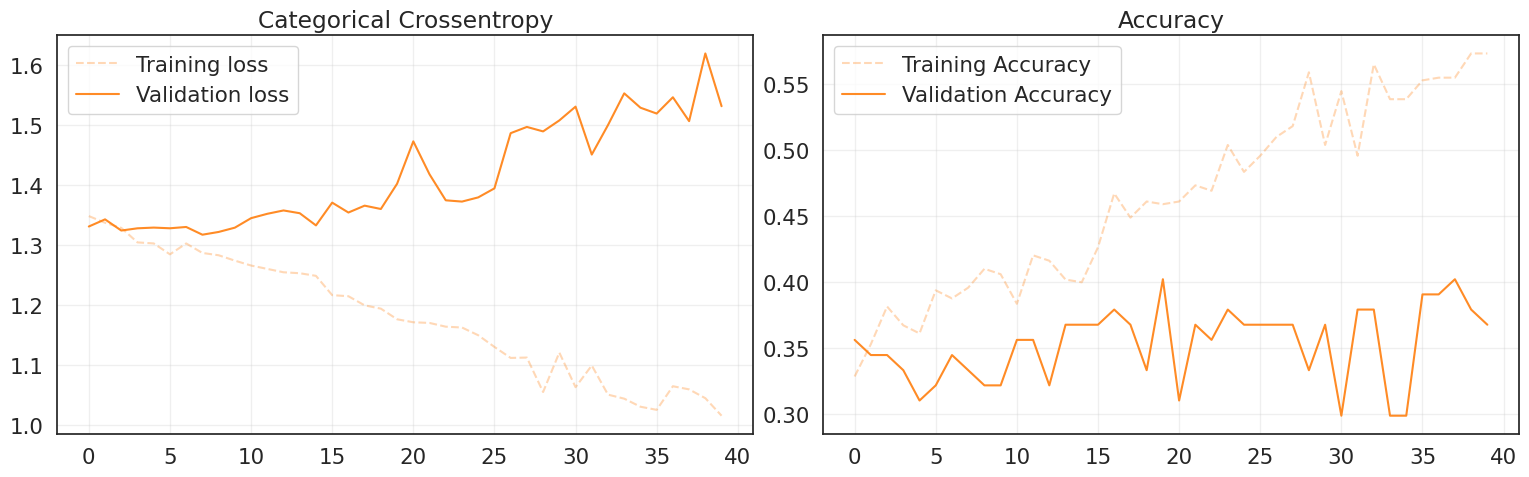

In [ ]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_acc'], label='Training Accuracy', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_acc'], label='Validation Accuracy', alpha=0.9, color='#ff7f0e')
ax2.set_title('Accuracy')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.4023
Precision over the validation set: 0.3978
Recall over the validation set: 0.4023
F1 score over the validation set: 0.3784


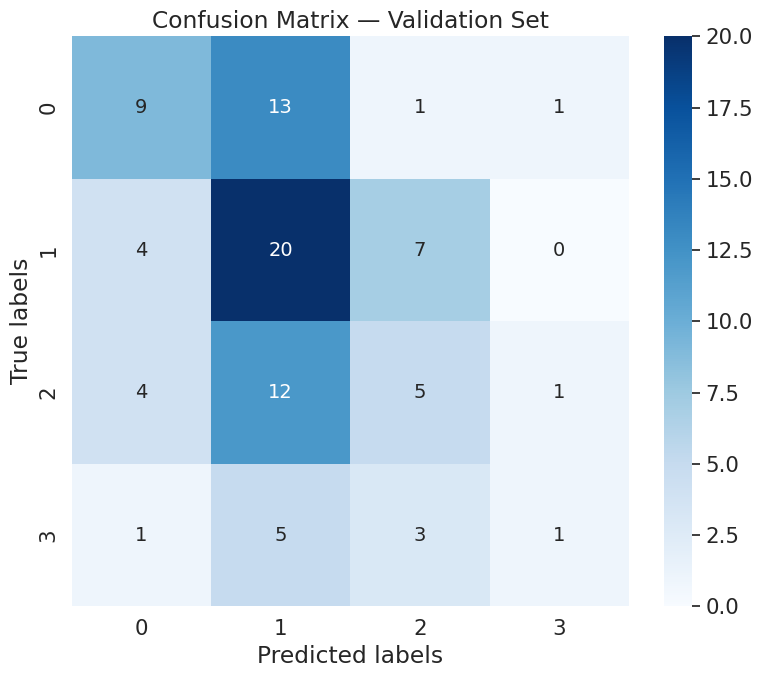

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_ft_loader: # Modificato da val_aug_loader a val_tl_loader
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = ft_model(xb) # Modificato da aug_model a tl_model
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()